In [1]:
# !rm -rf /home/yuz299/.local/lib/python3.11/site-packages/numpy*

In [2]:
# !rm -rf ./save
!rm -rf ./data/obesity_pert_sanity

### TODOs: 
1. add the other eval metric
2. finish post processing
3. convert to script and run it on remote server
4. get ready for the two genes perturbation challenge

# Fine-tune Pre-Trained scGPT for Obesity Perturbation Prediction

Following [this tutorial](https://github.com/bowang-lab/scGPT/blob/main/tutorials/Tutorial_Perturbation.ipynb) \
Competition Overview: [here](https://docs.google.com/viewerng/viewer?url=https://crunchdao--competition--production.s3.eu-west-1.amazonaws.com/competitions/broad-obesity-1/documents/broad-obesity.pdf) \
Competition Site: [here](https://hub.crunchdao.com/competitions/broad-obesity-1)


In [3]:
import json
import os
import sys
import time
import copy
from pathlib import Path
from typing import Iterable, List, Tuple, Dict, Union, Optional
import warnings
import gc

import torch
import numpy as np
import matplotlib
from torch import nn
from torch.nn import functional as F
from torchtext.vocab import Vocab
from torchtext._torchtext import (
    Vocab as VocabPybind,
)
from torch_geometric.loader import DataLoader
from torchmetrics.classification import MulticlassF1Score
from gears import PertData, GEARS
from gears.inference import compute_metrics, deeper_analysis, non_dropout_analysis
from gears.utils import create_cell_graph_dataset_for_prediction

sys.path.insert(0, "../")

import scgpt as scg
from scgpt.model import TransformerGenerator
from scgpt.loss import (
    masked_mse_loss,
    criterion_neg_log_bernoulli,
    masked_relative_error,
)
from scgpt.tokenizer import tokenize_batch, pad_batch, tokenize_and_pad_batch
from scgpt.tokenizer.gene_tokenizer import GeneVocab
from scgpt.utils import set_seed, map_raw_id_to_vocab_id, compute_perturbation_metrics

matplotlib.rcParams["savefig.transparent"] = False
warnings.filterwarnings("ignore")
os.environ['CUDA_LAUNCH_BLOCKING'] = "1"

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [7]:
import os
path = "./data/obesity_pert_sanity"
if os.path.isdir(path):
    print("Contents:", os.listdir(path))
else:
    print("❌ Path not found.")

Contents: ['data_pyg', 'perturb_processed.h5ad', 'splits']


### Load preprocessed data

In [4]:
import scanpy as sc

In [5]:
file_path = "../data/obesity_pert.h5ad" # 44846 cells x 11046 genes
adata = sc.read_h5ad(file_path)
print("orig shape:", adata.shape)

orig shape: (44846, 11046)


In [6]:
adata.var_names = adata.var["gene_name"].astype(str)
adata.var['gene_name'] = adata.var['gene_name'].astype(str)

# gears wants perturbed gene to be listed as a feature in var_names, and FLI1 is not there
adata = adata[~adata.obs['condition'].str.contains('FLI1')].copy()

# remove some duplicated gene names that were left out in preprocessing
manual_mapping = {
    "TMSB15B-AS1": "TMSB15B.1",
    "BHLHE40": "DEC1",
    "H2BC5": "HIST1H2BC",
    "WARS2": "WARS",
    "SLA2": "MARS",
}
dups_to_delete = ["TMSB15B.1", "DEC1", "WARS", "MARS", "HIST1H2BC"]

mask = adata.var['prev_gene_name'].isin(dups_to_delete)
adata.var.loc[mask, 'gene_name'] = adata.var.loc[mask, 'gene_name'].map(manual_mapping)
adata.var_names = adata.var['gene_name'].values

In [7]:
adata.X = adata.layers['counts']
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
# sc.pp.highly_variable_genes(adata, n_top_genes=5000, subset=True)

subset_size = 1000
sc.pp.highly_variable_genes(adata, n_top_genes=subset_size, subset=False)
hvg_indices = np.where(adata.var["highly_variable"].values)[0]
hvg_mask = torch.tensor(adata.var["highly_variable"].values, device=device)

## Train Configs

In [8]:
# settings for data prcocessing
pad_token = "<pad>"
special_tokens = [pad_token, "<cls>", "<eoc>"]
pad_value = 0  # for padding values
pert_pad_id = 0
include_zero_gene = "all"

# if sanity testing on datahub or not
sanity_test = True

# local sanity run config
max_seq_len = 512 if sanity_test else 1536

# settings for training
MLM = True  # whether to use masked language modeling, currently it is always on.
CLS = True  # celltype classification objective
CCE = False  # Contrastive cell embedding objective
MVC = False  # Masked value prediction for cell embedding
ECS = False  # Elastic cell similarity objective
amp = True
load_model = None # "../../scGPT_human"
load_param_prefixs = [
    "encoder",
    "value_encoder",
    "transformer_encoder",
]

# settings for optimizer
lr = 1e-4  # or 1e-4
batch_size = 2 if sanity_test else 64 # local sanity run config change
eval_batch_size = 2 if sanity_test else 64 # local sanity run config change
epochs = 2 if sanity_test else 15
schedule_interval = 1
early_stop = 10

# settings for the model
embsize = 128 if sanity_test else 512  # embedding dimension
d_hid = 128 if sanity_test else 512  # dimension of the feedforward network model in nn.TransformerEncoder
nlayers = 4 if sanity_test else 12  # number of nn.TransformerEncoderLayer in nn.TransformerEncoder
nhead = 4 if sanity_test else 8  # number of heads in nn.MultiheadAttention
n_layers_cls = 3
dropout = 0  # dropout probability
use_fast_transformer = False  # whether to use fast transformer

# logging
log_interval = 100

# dataset and eval choices
data_name = 'obesity_pert_sanity'
split = "simulation"

pert_to_pred = 'MEF2A+ctrl' if sanity_test else None

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [9]:
# random sample 1100 cells for sanity test runs
if sanity_test:
    np.random.seed(42)
    keep_perts = ['MEF2A+ctrl', 'TEAD1+ctrl', 'TFAP2A+ctrl']
    n_ctrl_keep = 200
    
    mask = adata.obs["condition"].isin(keep_perts + ["ctrl"])
    adata_sub = adata[mask].copy()
    
    ctrl_mask = adata_sub.obs["condition"] == "ctrl"
    ctrl_idx = np.where(ctrl_mask)[0]
    pert_idx = np.where(~ctrl_mask)[0]
    
    ctrl_keep = np.random.choice(ctrl_idx,size=min(n_ctrl_keep, len(ctrl_idx)), replace=False )
    
    adata_sub = adata_sub[np.concatenate([pert_idx, ctrl_keep])].copy()
    
    # free memory
    del adata
    del mask, ctrl_mask, ctrl_idx, pert_idx, ctrl_keep
    gc.collect()

    print(adata_sub.obs['gene'].value_counts())

gene
MEF2A     300
TEAD1     300
TFAP2A    300
NC        200
Name: count, dtype: int64


In [10]:
# if torch.cuda.is_available():
#     total_vram = torch.cuda.get_device_properties(0).total_memory / 1e9
#     if total_vram < 12:
#         batch_size = 8  # Safety for crappy GPUs
#     elif total_vram < 20:
#         batch_size = 32 # Safety for mid-tier
#     else:
#         batch_size = 64

In [11]:
save_dir = Path(f"./save/dev_perturb_{data_name}-{time.strftime('%b%d-%H-%M')}/")
save_dir.mkdir(parents=True, exist_ok=True)
print(f"saving to {save_dir}")

logger = scg.logger
scg.utils.add_file_handler(logger, save_dir / "run.log")
# log running date and current git commit
logger.info(f"Running on {time.strftime('%Y-%m-%d %H:%M:%S')}")

saving to save/dev_perturb_obesity_pert_sanity-Apr06-21-07
scGPT - INFO - Running on 2026-04-06 21:07:53


In [12]:
pert_data = PertData("./data")
pert_data.new_data_process(dataset_name=data_name, adata=adata_sub)

Mapped 4 cell types to indices.
Creating pyg object for each cell in the data...
100%|██████████| 4/4 [00:01<00:00,  2.47it/s]
Saving new dataset pyg object at ./data/obesity_pert_sanity/data_pyg/cell_graphs.pkl
Done!


In [13]:
# pert_data = PertData("./data")
pert_data.load(data_path="./data/obesity_pert_sanity")
pert_data.prepare_split(split=split, seed=1)
pert_data.get_dataloader(batch_size=batch_size, test_batch_size=eval_batch_size)

Mapped 4 cell types to indices.
Local copy of pyg dataset is detected. Loading...
Done!
Creating new splits....
Saving new splits at ./data/obesity_pert_sanity/splits/obesity_pert_sanity_simulation_1_0.75.pkl
Simulation split test composition:
combo_seen0:0
combo_seen1:0
combo_seen2:0
unseen_single:1
Done!
Creating dataloaders....
Done!


In [14]:
if load_model is not None:
    model_dir = Path(load_model)
    model_config_file = model_dir / "args.json"
    model_file = model_dir / "best_model.pt"
    vocab_file = model_dir / "vocab.json"

    vocab = GeneVocab.from_file(vocab_file)
    for s in special_tokens:
        if s not in vocab:
            vocab.append_token(s)

    pert_data.adata.var["id_in_vocab"] = [
        1 if gene in vocab else -1 for gene in pert_data.adata.var["gene_name"]
    ]
    gene_ids_in_vocab = np.array(pert_data.adata.var["id_in_vocab"])
    logger.info(
        f"match {np.sum(gene_ids_in_vocab >= 0)}/{len(gene_ids_in_vocab)} genes "
        f"in vocabulary of size {len(vocab)}."
    )
    genes = pert_data.adata.var["gene_name"].tolist()

    # model
    with open(model_config_file, "r") as f:
        model_configs = json.load(f)
    logger.info(
        f"Resume model from {model_file}, the model args will override the "
        f"config {model_config_file}."
    )
    embsize = model_configs["embsize"]
    nhead = model_configs["nheads"]
    d_hid = model_configs["d_hid"]
    nlayers = model_configs["nlayers"]
    n_layers_cls = model_configs["n_layers_cls"]
else:
    genes = pert_data.adata.var["gene_name"].tolist()
    vocab = Vocab(
        VocabPybind(genes + special_tokens, None)
    )  # bidirectional lookup [gene <-> int]
vocab.set_default_index(vocab["<pad>"])
gene_ids = np.array(
    [vocab[gene] if gene in vocab else vocab["<pad>"] for gene in genes], dtype=int
)
n_genes = len(genes)

cls_id = vocab["<cls>"]

## Create model and training functions

In [15]:
def convert_wqkv(pretrained_dict):
    new_dict = {}
    for k, v in pretrained_dict.items():
        if ".self_attn.Wqkv.weight" in k:
            new_dict[k.replace(".self_attn.Wqkv.weight", ".self_attn.in_proj_weight")] = v
        elif ".self_attn.Wqkv.bias" in k:
            new_dict[k.replace(".self_attn.Wqkv.bias", ".self_attn.in_proj_bias")] = v
        else:
            new_dict[k] = v
    return new_dict

In [16]:
ntokens = len(vocab)  # size of vocabulary
model = TransformerGenerator(
    ntokens,
    embsize,
    nhead,
    d_hid,
    nlayers,
    nlayers_cls=n_layers_cls,
    n_cls=4,
    vocab=vocab,
    dropout=dropout,
    pad_token=pad_token,
    pad_value=pad_value,
    pert_pad_id=pert_pad_id,
    use_fast_transformer=use_fast_transformer,
)
if load_param_prefixs is not None and load_model is not None:
    # only load params that start with the prefix
    model_dict = model.state_dict()
    pretrained_dict = torch.load(model_file)
    pretrained_dict = {
        k: v
        for k, v in pretrained_dict.items()
        if any([k.startswith(prefix) for prefix in load_param_prefixs])
    }
    # for k, v in pretrained_dict.items():
    #     logger.info(f"Loading params {k} with shape {v.shape}")

    print("renaming pretrained model keys to account for use_fast_transformer = False")
    pretrained_dict_renamed = convert_wqkv(pretrained_dict)
    model_dict.update(pretrained_dict_renamed)
    model.load_state_dict(model_dict, strict = False) # neglect key mismatches due to model architecture diff from use_fast_transformer = False
    
elif load_model is not None:
    try:
        model.load_state_dict(torch.load(model_file))
        logger.info(f"Loading all model params from {model_file}")
    except:
        # only load params that are in the model and match the size
        model_dict = model.state_dict()
        pretrained_dict = torch.load(model_file)
        pretrained_dict = {
            k: v
            for k, v in pretrained_dict.items()
            if k in model_dict and v.shape == model_dict[k].shape
        }
        for k, v in pretrained_dict.items():
            logger.info(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)
        
model.to(device)

TransformerGenerator(
  (encoder): GeneEncoder(
    (embedding): Embedding(11049, 128, padding_idx=11046)
    (enc_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  )
  (value_encoder): ContinuousValueEncoder(
    (dropout): Dropout(p=0, inplace=False)
    (linear1): Linear(in_features=1, out_features=128, bias=True)
    (activation): ReLU()
    (linear2): Linear(in_features=128, out_features=128, bias=True)
    (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  )
  (pert_encoder): Embedding(3, 128, padding_idx=0)
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=128, bias=True)
        (dropout): Dropout(p=0, inplace=False)
        (linear2): Linear(in_features=128, out_features=128, bias=True)

In [17]:
criterion = masked_mse_loss
criterion_cls = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, schedule_interval, gamma=0.9)
scaler = torch.cuda.amp.GradScaler(enabled=amp)


def train(model: nn.Module, train_loader: torch.utils.data.DataLoader) -> None:
    """
    Train the model for one epoch.
    """
    model.train()
    total_loss, total_mse, total_ce = 0.0, 0.0, 0.0
    start_time = time.time()

    num_batches = len(train_loader)
    for batch, batch_data in enumerate(train_loader):
        batch_size = len(batch_data.y)
        batch_data.to(device)
        x: torch.Tensor = batch_data.x  # (batch_size * n_genes, 2)
        ori_gene_values = x[:, 0].view(batch_size, n_genes)
        pert_flags = x[:, 1].long().view(batch_size, n_genes)
        target_gene_values = batch_data.y  # (batch_size, n_genes)
        target_cell_types = batch_data.cell_type # (batch_size,)

        if include_zero_gene in ["all", "batch-wise"]:
            # if include_zero_gene == "all":
            #     input_gene_ids = torch.arange(n_genes, device=device, dtype=torch.long)
            # else:
            #     input_gene_ids = (
            #         ori_gene_values.nonzero()[:, 1].flatten().unique().sort()[0]
            #     )
            # # sample input_gene_id
            # if len(input_gene_ids) > max_seq_len:
            #     input_gene_ids = torch.randperm(len(input_gene_ids), device=device)[
            #         :max_seq_len
            #     ]
            
           # --- START NEW SELECTION LOGIC ---
            # 1. Get all genes that are non-zero in this batch
            active_ids = ori_gene_values.nonzero()[:, 1].unique()

            # 2. Intersect with HVGs (Ensure hvg_indices is a tensor on the correct device)
            hvg_ids_t = torch.as_tensor(hvg_indices, device=device)
            mask = torch.isin(active_ids, hvg_ids_t)
            active_hvgs = active_ids[mask]

            # 3. Handle sequence length constraints
            if len(active_hvgs) > max_seq_len:
                # If active HVGs exceed limit, take the first N (usually pre-sorted by variance)
                input_gene_ids = active_hvgs[:max_seq_len]
            else:
                # Fill remaining slots with other non-zero genes
                remaining_slots = max_seq_len - len(active_hvgs)
                other_ids = active_ids[~mask]
                
                num_to_fill = min(len(other_ids), remaining_slots)
                random_fill = other_ids[torch.randperm(len(other_ids))[:num_to_fill]]
                input_gene_ids = torch.cat([active_hvgs, random_fill])
                
            input_values = ori_gene_values[:, input_gene_ids]
            input_pert_flags = pert_flags[:, input_gene_ids]
            target_values = target_gene_values[:, input_gene_ids]

            # mapped_input_gene_ids = map_raw_id_to_vocab_id(input_gene_ids, gene_ids)
            # mapped_input_gene_ids = mapped_input_gene_ids.repeat(batch_size, 1)

            # # src_key_padding_mask = mapped_input_gene_ids.eq(vocab[pad_token])
            # src_key_padding_mask = torch.zeros_like(
            #     input_values, dtype=torch.bool, device=device
            # )

            # 1. Map gene IDs
            mapped_input_gene_ids = map_raw_id_to_vocab_id(input_gene_ids, gene_ids)
            mapped_input_gene_ids = mapped_input_gene_ids.repeat(batch_size, 1)
            
            # 2. PREPEND CLS TOKEN (Crucial Fix)
            cls_id = vocab["<cls>"]
            cls_ids = torch.full((batch_size, 1), cls_id, dtype=torch.long, device=device)
            mapped_input_gene_ids = torch.cat([cls_ids, mapped_input_gene_ids], dim=1)
            
            # 3. Prepend 0.0 to values and 0 to pert_flags to match the CLS token
            cls_values = torch.zeros((batch_size, 1), device=device)
            input_values = torch.cat([cls_values, input_values], dim=1)
            
            cls_flags = torch.zeros((batch_size, 1), dtype=torch.long, device=device)
            input_pert_flags = torch.cat([cls_flags, input_pert_flags], dim=1)
            
            # 4. Update the padding mask to account for the extra token
            src_key_padding_mask = torch.zeros_like(input_values, dtype=torch.bool, device=device)
            # (Ensure target_values also matches the length if your loss function expects it)

        with torch.cuda.amp.autocast(enabled=amp):
            output_dict = model(
                mapped_input_gene_ids,
                input_values,
                input_pert_flags,
                src_key_padding_mask=src_key_padding_mask,
                CLS=CLS,
                CCE=CCE,
                MVC=MVC,
                ECS=ECS,
            )
            output_values = output_dict["mlm_output"][:, 1:]
            cls_values = output_dict['cls_output']

            masked_positions = torch.ones_like(
                target_values, dtype=torch.bool
            )  # Use all
            
            loss_mse = criterion(output_values, target_values, masked_positions)
            loss_ce = criterion_cls(cls_values, target_cell_types)
            loss = loss_mse + loss_ce

        model.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        with warnings.catch_warnings(record=True) as w:
            warnings.filterwarnings("always")
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0,
                error_if_nonfinite=False if scaler.is_enabled() else True,
            )
            if len(w) > 0:
                logger.warning(
                    f"Found infinite gradient. This may be caused by the gradient "
                    f"scaler. The current scale is {scaler.get_scale()}. This warning "
                    "can be ignored if no longer occurs after autoscaling of the scaler."
                )
        scaler.step(optimizer)
        scaler.update()

        # torch.cuda.empty_cache()

        total_loss += loss.item()
        total_mse += loss_mse.item()
        total_ce += loss_ce.item()
        if batch % log_interval == 0 and batch > 0:
            lr = scheduler.get_last_lr()[0]
            ms_per_batch = (time.time() - start_time) * 1000 / log_interval
            cur_loss = total_loss / log_interval
            cur_mse = total_mse / log_interval
            cur_ce = total_ce / log_interval
            # ppl = math.exp(cur_loss)
            logger.info(
                f"| epoch {epoch:3d} | {batch:3d}/{num_batches:3d} batches | "
                f"lr {lr:05.4f} | ms/batch {ms_per_batch:5.2f} | "
                f"loss {cur_loss:5.2f} | mse {cur_mse:5.2f} | ce {cur_ce:5.2f}|"
            )
            total_loss = 0
            total_mse = 0
            total_ce = 0
            start_time = time.time()


def eval_perturb(
    loader: DataLoader, model: TransformerGenerator, device: torch.device
) -> Dict:
    """
    Run model in inference mode using a given data loader
    """

    model.eval()
    model.to(device)
    pert_cat = []
    pred = []
    truth = []
    pred_de = []
    truth_de = []
    results = {}

    # Storage for classification proportions (Program-level metrics)
    all_preds_cls = []
    all_truth_cls = []

    total_loss = 0.0
    total_correct = 0
    total_cells = 0

    f1_metric = MulticlassF1Score(num_classes=4, average="macro").to(device)
    
    # {'adipo': 0, 'lipo': 1, 'other': 2, 'pre_adipo': 3}
    ADIPO_IDX = 0
    LIPO_IDX = 1
    OTHER_IDX = 2
    PRE_ADIPO_IDX = 3

    for itr, batch in enumerate(loader):
        batch.to(device)
        pert_cat.extend(batch.pert)    

        with torch.no_grad():              
            p, cls_values= model.pred_perturb(
                batch,
                include_zero_gene=include_zero_gene,
                gene_ids=gene_ids,
                cls_id=cls_id,
            )

            # predicted cell type values / truth values
            target_cell_types = batch.cell_type
            loss = criterion_cls(cls_values, target_cell_types)
            preds = cls_values.argmax(1)
            
            total_loss += loss.item() * batch_size
            total_correct += (preds == target_cell_types).sum().item()
            total_cells += batch_size
            f1_metric.update(preds, target_cell_types)

            all_preds_cls.append(preds.cpu())
            all_truth_cls.append(target_cell_types.cpu())

            # predicted gene expression values / truth values
            t = batch.y
            pred.extend(p.cpu())
            truth.extend(t.cpu())

            # Differentially expressed genes
            for it, de_idx in enumerate(batch.de_idx):
                pred_de.append(p[it, de_idx])
                truth_de.append(t[it, de_idx])

    # --- Aggregate Perturbed Expression Results ---
    # all gene expressions
    results["pert_cat"] = np.array(pert_cat)
    pred = torch.stack(pred)
    truth = torch.stack(truth)
    results["pred"] = pred.detach().cpu().numpy().astype(np.float32)
    results["truth"] = truth.detach().cpu().numpy().astype(np.float32)

    # de gene expressions
    pred_de = torch.stack(pred_de)
    truth_de = torch.stack(truth_de)
    results["pred_de"] = pred_de.detach().cpu().numpy().astype(np.float32)
    results["truth_de"] = truth_de.detach().cpu().numpy().astype(np.float32)

    # --- Aggregate Classification Metrics ---
    # cls metrics
    results["cls_loss"] = total_loss / total_cells if total_cells > 0 else 0
    # results["cls_acc"] = total_correct / total_cells if total_cells > 0 else 0
    results["cls_f1"] = f1_metric.compute().item()

    # l1-distance (program level) calculation
    all_preds_cls = torch.cat(all_preds_cls).numpy()
    all_truth_cls = torch.cat(all_truth_cls).numpy()
    pert_array = np.array(pert_cat)
    
    unique_perts = np.unique(pert_array)
    program_losses = []

    for p_name in unique_perts:
        mask = (pert_array == p_name)
        p_preds = all_preds_cls[mask]
        p_truth = all_truth_cls[mask]

        def get_s_metrics(labels):
            counts = np.bincount(labels, minlength=4)
            props = counts / len(labels)
            
            # S^R = [preadipo, adipo, other]
            s_r = np.array([props[PRE_ADIPO_IDX], props[ADIPO_IDX], props[OTHER_IDX]])
            
            # S_L = lipo / adipo
            s_l = props[LIPO_IDX] / (props[ADIPO_IDX] + 1e-6) # +1e-6 to avoid division by 0
            return s_r, s_l

        s_r_truth, s_l_truth = get_s_metrics(p_truth)
        s_r_pred, s_l_pred = get_s_metrics(p_preds)

        # Formula: 0.75 * L1(S_R) + 0.25 * L1(S_L)
        l1_sr = np.sum(np.abs(s_r_pred - s_r_truth))
        l1_sl = np.abs(s_l_pred - s_l_truth)
        
        p_loss = (0.75 * l1_sr) + (0.25 * l1_sl)
        program_losses.append(p_loss)

    results["l1_distance"] = np.mean(program_losses) if program_losses else 0

    return results

In [18]:
# for name, param in model.cls_decoder.named_parameters():
#     if not param.requires_grad:
#         print(f"Layer {name} is FROZEN!")

## Train

In [19]:
best_val_loss = float("inf")
best_val_corr = 0
best_model = None
patience = 0

for epoch in range(1, epochs + 1):
    epoch_start_time = time.time()
    train_loader = pert_data.dataloader["train_loader"]
    valid_loader = pert_data.dataloader["val_loader"]

    train(
        model,
        train_loader,
    )

    val_res = eval_perturb(valid_loader, model, device)
    val_metrics = compute_perturbation_metrics(
        val_res, pert_data.adata[pert_data.adata.obs["condition"] == "ctrl"]
    )
    val_metrics.update({
        "cls_loss": val_res["cls_loss"],
        # "cls_acc": val_res["cls_acc"],
        "cls_f1": val_res["cls_f1"],
        "l1_distance": val_res["l1_distance"],
    })
    logger.info(f"val_metrics at epoch {epoch}: ")
    logger.info(val_metrics)

    elapsed = time.time() - epoch_start_time
    logger.info(f"| end of epoch {epoch:3d} | time: {elapsed:5.2f}s | ")

    val_score = val_metrics["pearson_delta"]
    if val_score > best_val_corr:
        best_val_corr = val_score
        best_model = copy.deepcopy(model)
        logger.info(f"Best model with score {val_score:5.4f}")
        patience = 0
    else:
        patience += 1
        if patience >= early_stop:
            logger.info(f"Early stop at epoch {epoch}")
            break

    # torch.save(
    #     model.state_dict(),
    #     save_dir / f"model_{epoch}.pt",
    # )

    scheduler.step()

scGPT - INFO - | epoch   1 | 100/250 batches | lr 0.0001 | ms/batch 26.24 | loss  2.09 | mse  0.83 | ce  1.26|
scGPT - INFO - | epoch   1 | 200/250 batches | lr 0.0001 | ms/batch 20.48 | loss  1.93 | mse  0.67 | ce  1.26|
scGPT - INFO - val_metrics at epoch 1: 
scGPT - INFO - {'pearson': 0.9737084559721597, 'pearson_de': 0.9864340423103973, 'pearson_delta': 0.11700629478148436, 'pearson_de_delta': 0.7190783508511193, 'mmd': 0.13971718749999984, 'cls_loss': 1.3088704427083333, 'cls_f1': 0.13414634764194489, 'l1_distance': 1.0812483593873046}
scGPT - INFO - | end of epoch   1 | time: 18.40s | 
scGPT - INFO - Best model with score 0.1170
scGPT - INFO - | epoch   2 | 100/250 batches | lr 0.0001 | ms/batch 25.17 | loss  1.98 | mse  0.72 | ce  1.26|
scGPT - INFO - | epoch   2 | 200/250 batches | lr 0.0001 | ms/batch 21.37 | loss  1.96 | mse  0.71 | ce  1.25|
scGPT - INFO - val_metrics at epoch 2: 
scGPT - INFO - {'pearson': 0.9755214656804341, 'pearson_de': 0.9927915953375775, 'pearson_delta

In [20]:
# # save model
# if best_model is None:
#     best_model = model
# torch.save(best_model.state_dict(), save_dir / "obesity_perturb_best_model_sanity.pt")

## Evaluations

In [21]:
def predict(
    model: TransformerGenerator, pert_list: List[str], pool_size: Optional[int] = None, is_submission: bool = False,
) -> Dict:
    """
    Predict the gene expression values for the given perturbations.

    Args:
        model (:class:`torch.nn.Module`): The model to use for prediction.
        pert_list (:obj:`List[str]`): The list of perturbations to predict.
        pool_size (:obj:`int`, optional): For each perturbation, use this number
            of cells in the control and predict their perturbation results. Report
            the stats of these predictions. If `None`, use all control cells.
    """
    adata = pert_data.adata
    ctrl_adata = adata[adata.obs["condition"] == "ctrl"]
    if pool_size is None:
        pool_size = len(ctrl_adata.obs)
    gene_list = pert_data.gene_names.values.tolist()
    for pert in pert_list:
        for i in pert:
            if i not in gene_list:
                raise ValueError(
                    "The gene is not in the perturbation graph. Please select from GEARS.gene_list!"
                )

    model.eval()
    device = next(model.parameters()).device
    with torch.no_grad():
        results_pred = {}
        results_pred_cls = {}
        for pert in pert_list:
            cell_graphs = create_cell_graph_dataset_for_prediction(
                pert, ctrl_adata, gene_list, device, num_samples=pool_size
            )
            loader = DataLoader(cell_graphs, batch_size=eval_batch_size, shuffle=False)
            preds = []
            preds_cls = []
            for batch_data in loader:
                pred_gene_values, cls_values = model.pred_perturb(
                    batch_data, include_zero_gene, gene_ids=gene_ids, cls_id=cls_id, amp=amp
                )
                preds.append(pred_gene_values.cpu())
                preds_cls.append(cls_values.cpu())
            preds = torch.cat(preds, dim=0)
            preds_cls = torch.cat(preds_cls, dim = 0)
            if is_submission:
                results_pred["_".join(pert)] = preds.numpy() # Shape: (pool_size, num_genes)
            else:
                results_pred["_".join(pert)] = np.mean(preds.numpy(), axis=0)

            results_pred_cls["_".join(pert)] = preds_cls.numpy() # (pool_size, 4)

    return results_pred, results_pred_cls

In [22]:
def plot_perturbation(
    model: nn.Module, query: str, save_file: str = None, pool_size: int = None
) -> matplotlib.figure.Figure:
    import matplotlib.pyplot as plt
    import numpy as np
    import seaborn as sns

    sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1.5)

    adata = pert_data.adata
    gene2idx = pert_data.node_map
    cond2name = dict(adata.obs[["condition", "condition_name"]].values)
    gene_raw2id = dict(zip(adata.var.index.values, adata.var.gene_name.values))

    de_idx = [
        gene2idx[gene_raw2id[i]]
        for i in adata.uns["top_non_dropout_de_20"][cond2name[query]]
    ]
    genes = [
        gene_raw2id[i] for i in adata.uns["top_non_dropout_de_20"][cond2name[query]]
    ]
    truth = adata[adata.obs.condition == query].X.toarray()[:, de_idx]
    if query.split("+")[1] == "ctrl":
        pred, _ = predict(model, [[query.split("+")[0]]], pool_size=pool_size)
        pred = pred[query.split("+")[0]][de_idx]
    else:
        pred, _ = predict(model, [query.split("+")], pool_size=pool_size)
        pred = pred["_".join(query.split("+"))][de_idx]
    ctrl_means = adata[adata.obs["condition"] == "ctrl"].to_df().mean()[de_idx].values

    pred = pred - ctrl_means
    truth = truth - ctrl_means

    fig, ax = plt.subplots(figsize=[16.5, 4.5])
    plt.title(query)
    plt.boxplot(truth, showfliers=False, medianprops=dict(linewidth=0))

    for i in range(pred.shape[0]):
        _ = plt.scatter(i + 1, pred[i], color="red")

    plt.axhline(0, linestyle="dashed", color="green")

    ax.xaxis.set_ticklabels(genes, rotation=90)

    plt.ylabel("Change in Gene Expression over Control", labelpad=10)
    plt.tick_params(axis="x", which="major", pad=5)
    plt.tick_params(axis="y", which="major", pad=5)
    sns.despine()

    if save_file:
        fig.savefig(save_file, bbox_inches="tight", transparent=False)

    return fig

#### plots

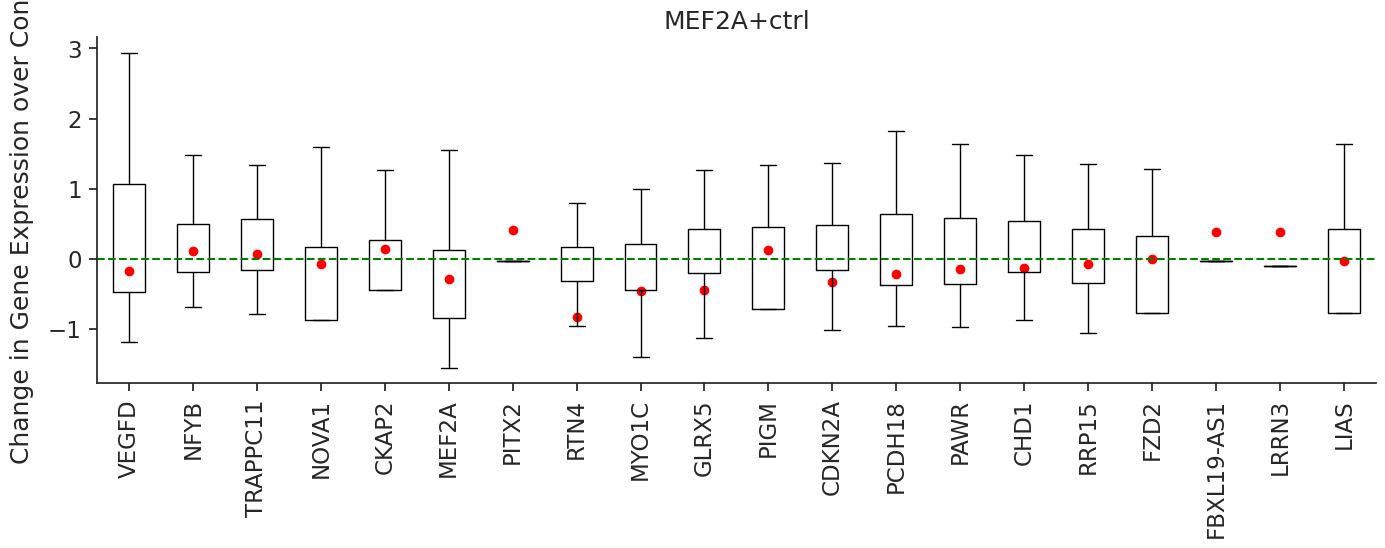

In [23]:
# for p in perts_to_plot:
#     plot_perturbation(best_model, p, pool_size=300, save_file=f"{save_dir}/{p}.png")

# only allows for in gene perturbations that are in the adata we fed in
try:
    plot_perturbation(best_model, pert_to_pred, save_file = None, pool_size=100); # f"{save_dir}/{pert_to_pred}.png"
except:
    print("no perturbed gene is provided for plotting")

#### evaluation on held-out test set

In [24]:
test_loader = pert_data.dataloader["test_loader"]
test_res = eval_perturb(test_loader, best_model, device)
# test_metrics, test_pert_res = compute_metrics(test_res)
test_metrics = compute_perturbation_metrics(
    test_res, pert_data.adata[pert_data.adata.obs["condition"] == "ctrl"]
)
test_metrics.update({
    "cls_loss": test_res["cls_loss"],
    # "cls_acc": val_res["cls_acc"],
    "cls_f1": test_res["cls_f1"],
    "l1_distance": test_res["l1_distance"],
})
print(test_metrics)

# save the dicts in json
with open(f"{save_dir}/test_metrics.json", "w") as f:
    json.dump(test_metrics, f)
# with open(f"{save_dir}/test_pert_res.json", "w") as f:
#     json.dump(test_pert_res, f)

deeper_res = deeper_analysis(pert_data.adata, test_res)
non_dropout_res = non_dropout_analysis(pert_data.adata, test_res)

metrics = ["pearson_delta", "pearson_delta_de"]
metrics_non_dropout = [
    "pearson_delta_top20_de_non_dropout",
    "pearson_top20_de_non_dropout",
]
subgroup_analysis = {}
for name in pert_data.subgroup["test_subgroup"].keys():
    subgroup_analysis[name] = {}
    for m in metrics:
        subgroup_analysis[name][m] = []

    for m in metrics_non_dropout:
        subgroup_analysis[name][m] = []

for name, pert_list in pert_data.subgroup["test_subgroup"].items():
    for pert in pert_list:
        for m in metrics:
            subgroup_analysis[name][m].append(deeper_res[pert][m])

        for m in metrics_non_dropout:
            subgroup_analysis[name][m].append(non_dropout_res[pert][m])

for name, result in subgroup_analysis.items():
    for m in result.keys():
        mean_value = np.mean(subgroup_analysis[name][m])
        logger.info("test_" + name + "_" + m + ": " + str(mean_value))

{'pearson': 0.9713733254256811, 'pearson_de': 0.9730608274823761, 'pearson_delta': -0.013169817834071148, 'pearson_de_delta': -0.004226923072177853, 'mmd': 0.14319331597222207, 'cls_loss': 1.4018782552083333, 'cls_f1': 0.12871287763118744, 'l1_distance': 1.0382250650400078}
scGPT - INFO - test_combo_seen0_pearson_delta: nan
scGPT - INFO - test_combo_seen0_pearson_delta_de: nan
scGPT - INFO - test_combo_seen0_pearson_delta_top20_de_non_dropout: nan
scGPT - INFO - test_combo_seen0_pearson_top20_de_non_dropout: nan
scGPT - INFO - test_combo_seen1_pearson_delta: nan
scGPT - INFO - test_combo_seen1_pearson_delta_de: nan
scGPT - INFO - test_combo_seen1_pearson_delta_top20_de_non_dropout: nan
scGPT - INFO - test_combo_seen1_pearson_top20_de_non_dropout: nan
scGPT - INFO - test_combo_seen2_pearson_delta: nan
scGPT - INFO - test_combo_seen2_pearson_delta_de: nan
scGPT - INFO - test_combo_seen2_pearson_delta_top20_de_non_dropout: nan
scGPT - INFO - test_combo_seen2_pearson_top20_de_non_dropout: 

## Inference

predict_perturbations: 2863 perturbed gene names that we need to predict \
genes_to_predict: 10238 genes that we need to predict values of, we choose to use all genes during training and inference then slice it based on this

In [25]:
# load the files 
with open("../data/genes_to_predict.txt", 'r') as f:
    genes_to_predict = f.read().splitlines()
    
with open("../data/predict_perturbations.txt", 'r') as f:
    predict_perturbations = f.read().splitlines()

predict_perturbations_list = [[predict_perturbations[0]], [predict_perturbations[1]]] if sanity_test else [[perturb_gene] for perturb_gene in predict_perturbations]

In [26]:
# predict our results
pred_result, pred_cls_result = predict(best_model, predict_perturbations_list, pool_size = 100, is_submission = True)

In [27]:
print(len(pred_result))
print(pred_result['LUZP1'].shape)
pred_result['LUZP1']


2
(100, 11046)


array([[0.36035156, 0.49438477, 1.6515316 , ..., 0.50634766, 0.4790039 ,
        0.7461846 ],
       [0.6529342 , 0.4951172 , 0.49243164, ..., 0.50634766, 0.4794922 ,
        1.0823426 ],
       [0.60175425, 0.49731445, 1.1327889 , ..., 0.50878906, 0.48217773,
        1.0945364 ],
       ...,
       [0.3618164 , 0.49536133, 1.3674265 , ..., 0.50683594, 0.47998047,
        0.41137695],
       [0.6842625 , 0.49438477, 1.3022687 , ..., 0.50634766, 0.47875977,
        0.75036657],
       [0.6487495 , 0.4963379 , 0.83323926, ..., 0.50878906, 0.48095703,
        0.91559994]], dtype=float32)

In [28]:
pred_cls_result

{'MYADM': array([[-0.4202, -1.308 ,  0.4863,  0.9434],
        [-0.4246, -1.308 ,  0.4753,  0.9263],
        [-0.4224, -1.308 ,  0.4807,  0.9336],
        [-0.4229, -1.308 ,  0.4802,  0.9336],
        [-0.4238, -1.309 ,  0.4775,  0.9307],
        [-0.423 , -1.308 ,  0.479 ,  0.9316],
        [-0.4248, -1.308 ,  0.4753,  0.926 ],
        [-0.4246, -1.308 ,  0.474 ,  0.925 ],
        [-0.4229, -1.308 ,  0.4802,  0.9336],
        [-0.423 , -1.308 ,  0.4797,  0.933 ],
        [-0.4233, -1.308 ,  0.48  ,  0.934 ],
        [-0.4255, -1.308 ,  0.4739,  0.9243],
        [-0.4236, -1.308 ,  0.477 ,  0.9297],
        [-0.424 , -1.308 ,  0.4763,  0.9287],
        [-0.423 , -1.308 ,  0.479 ,  0.9316],
        [-0.4229, -1.308 ,  0.481 ,  0.935 ],
        [-0.4233, -1.309 ,  0.4788,  0.931 ],
        [-0.4216, -1.308 ,  0.4846,  0.9414],
        [-0.423 , -1.308 ,  0.4783,  0.93  ],
        [-0.4258, -1.308 ,  0.4731,  0.9224],
        [-0.424 , -1.308 ,  0.477 ,  0.929 ],
        [-0.4204, -1.308 

### Post-processing

scGPT cannot predict perturbations for genes not in adata.var.index out-of-the-box, so need a workaround

In [29]:
# # identify the 4 that are missing
# perturb_genes_not_in_gene_list = []
# for perturb_gene in predict_perturbations:
#     if(perturb_gene not in pert_data.adata.var['gene_name']):
#         perturb_genes_not_in_gene_list.append(perturb_gene)

In [30]:
# # option 1: fill by per-gene control mean expression across all cells

# # compute
# n_cells_to_fill = 100
# ctrl_adata = pert_data.adata[pert_data.adata.obs['condition'] == 'ctrl']
# ctrl_mean_vector = np.array(ctrl_adata.X.mean(axis=0)).flatten()  # shape (n_genes,)
# filled_matrix = np.tile(ctrl_mean_vector, (n_cells_to_fill, 1)) # shape (100, n_genes)

# # add to the pred_result
# for perturb_gene in perturb_genes_not_in_gene_list:
#     pred_result[perturb_gene] = filled_matrix

In [31]:
# # option 2: include the missing genes in training data --> not viable due to not matching scGPT vocab
# vocab_path = os.path.join(os.path.dirname(scg.__file__), "tokenizer", "default_gene_vocab.json")

# # check gene vocab overlap
# vocab = GeneVocab.from_file(vocab_path)
# [g for g in perturb_genes_not_in_gene_list if g in vocab]

In [32]:
# option other?

## Save to AnnData format: do it later

I think we are ready to convert this to a script and run it on cluster